# Random forest: do its assumptions hold, and if so, how accurate is it?

**Goal:** give every booking a chance (0 to 1) of cancelling, then judge those chances the way the client does (`contract.py`).

A random forest grows many decision trees, each on a random sample of the bookings and looking at a random subset of the clues at every question, then averages their chances. Like a tree it needs no straight-line or scaling assumptions; its checklist is about *whether the trees are good enough and different enough for the average to help*.

**What this notebook does, in order**

1. **Set up** and load the bookings, split by time into *train* (the model learns), *choose* (we pick settings and the buffer) and *proof* (the final exam).
2. **Check the assumptions** of random forest on the train period.
3. **Gate.** If every *must-pass* assumption holds, we train. If one fails, the notebook stops and says which.
4. **Train** on train only.
5. **Accuracy**: ordinary classification scores on the choose period.
6. **Accuracy by the contract**: turn the chances into *k* (extra rooms to sell) and score euros, empty rooms, walked guests and walks per 1,000, next to the client's flat rule.
7. **Proof** (the final exam, off by default).

This notebook replaces the random forest part of `src/all_models.py`. The *k* step in section 6 is the same rule as in `06_k_calculator.ipynb`.

## 1. Set up

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 200)

# --- where is everything? (works whether Jupyter starts in notebooks/ or in the project root) ---
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "notes" / "features_simple.py").exists())
NOTES, SRC = ROOT / "notes", ROOT / "src"
for folder in (NOTES, SRC):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import data               # the starter's data.py: reads hotels.csv (and downloads it if it is missing)
import features_simple    # our cleaning + the Bin 1 clue columns (known on the day of booking)


def load_contract():
    """Load the client's scoring file. We use it exactly as it is and never edit it."""
    for folder in (NOTES, SRC, SRC / "__pycache__"):
        path = folder / "contract.py"
        if path.exists():
            spec = importlib.util.spec_from_file_location("contract", path)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            print("scoring file loaded from:", path.relative_to(ROOT))
            return module
    raise FileNotFoundError("contract.py was not found in notes/ or src/")


contract = load_contract()

# --- chart look: one blue line, one orange highlight, quiet grid, dark text ---
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
})

scoring file loaded from: src/__pycache__/contract.py


Three switches control the run:

| Switch | Default | Meaning |
|---|---|---|
| `TUNE` | `False` | `True` picks hyper-parameters by time-ordered cross-validation on **train only** (slower). `False` uses the fixed defaults below. |
| `RUN_PROOF` | `False` | The proof period is the final exam. Keep it `False` while experimenting. |
| `FORCE_TRAIN` | `False` | `True` trains even if a *must-pass* assumption fails. Not recommended. |

In [2]:
TUNE = False          # True  = pick hyper-parameters by time-ordered cross-validation on TRAIN (slower)
RUN_PROOF = False     # the proof period is the FINAL exam: leave this False until everything is decided
FORCE_TRAIN = False   # True  = train even if a MUST-PASS assumption fails (not recommended)


# Starting settings of the forest (used by the assumption checks and by training)
N_TREES = 200          # how many trees are averaged
MAX_DEPTH = 12         # at most 12 questions in a row
MIN_LEAF = 10          # every leaf must hold at least 10 bookings

## 2. Load the bookings and split them by time

In [3]:
raw = data.read_raw()                                     # every booking, exactly as exported
bookings = features_simple.clean_bookings(raw)            # the documented cleaning choices
train, choose, proof = contract.split_periods(bookings)   # split by arrival date, as the contract says
train, choose, proof = [features_simple.add_features(part) for part in (train, choose, proof)]

FEATURES = features_simple.bin1_features                  # the clues known on the day of booking
NUMERIC = features_simple.bin1_numeric_cols
CATEGORICAL = features_simple.bin1_categorical_cols

print(f"bookings: train {len(train):,} | choose {len(choose):,} | proof {len(proof):,}")
print("The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.")

bookings: train 49,108 | choose 29,482 | proof 40,619
The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.


## 3. Do the assumptions of a random forest hold?

We test them on the **train period only**. Each check is either **must pass** (FAIL stops the notebook) or **advisory** (WARN: noted, we still train).

**What a forest does *not* need**: no scaling, no straight-line relationships, no normal distributions. Correlated clues do not break it either (they only share the credit in the importance chart).

| # | Assumption | Why it matters here | How it is tested | Type |
|---|---|---|---|---|
| A1 | The outcome is yes/no | We grow classification trees | `is_canceled` holds only 0 and 1 | must pass |
| A2 | No leakage | A clue only known after the stay gives the answer away | no clue comes from Bin 2 or Bin 3 | must pass |
| A3 | No gaps | The pipeline has no imputer | count empty cells | must pass |
| A4 | Scoring columns present | `contract.nightly_table` needs them | check the names | must pass |
| A5 | Periods follow each other in time | Train before choose before proof | compare dates | must pass |
| A6 | Neither outcome is rare | With a rare outcome, accuracy is misleading | rarer outcome >= 10% | advisory |
| A7 | The past looks like the future | Trees cannot extrapolate beyond what they saw in train | cancel-rate gap and unseen values | must pass |
| R1 | Each tree is better than guessing | Averaging many useless trees stays useless: the forest needs *weak but real* learners | a single pilot tree must reach AUC >= 0.55 on unseen data | must pass |
| R2 | The trees can differ from each other | The average only helps if the trees make different mistakes: each question sees a random subset of the clues | clues per question (the square root of the encoded columns) is more than 1 and less than all | must pass |
| R3 | Enough of the rarer outcome | Leaves must be able to hold both answers | rarer outcome >= 10 x `MIN_LEAF` | must pass |
| R4 | No constant clue | A clue with one value can never split anything | count distinct values | advisory |
| R5 | No near-duplicate numeric clues | Two clues that say the same thing take turns being picked and split their importance | no pair with correlation >= 0.9 | advisory |
| | Enough trees | Too few trees leave the average noisy | **tested after fitting**: log loss vs number of trees, in section 4 | diagnostic |
| | Independent bookings | The chances of bookings on a night are added as if independent | **tested after fitting**, in section 6 | diagnostic |

In [4]:
CHECKS = []    # one row per assumption


def check(name, passed, evidence, must_pass=True):
    """Record one assumption.
       must_pass=True  -> if it fails the status is FAIL and training is stopped.
       must_pass=False -> if it fails the status is WARN: we note it and still train."""
    status = "PASS" if passed else ("FAIL" if must_pass else "WARN")
    CHECKS.append({"assumption": name, "status": status,
                   "type": "must pass" if must_pass else "advisory", "evidence": evidence})

def make_preparer(scale_numbers):
    """Turn the clue columns into numbers. Everything it learns, it learns from the rows it is fitted on."""
    text_step = OneHotEncoder(handle_unknown="ignore", min_frequency=20)   # rare values are grouped together
    number_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("text", text_step, CATEGORICAL),
        ("numbers", number_step, NUMERIC),
    ])

### A. Checks every model needs (data and contract)

In [5]:
y_train = train["is_canceled"]

# A1. the outcome is a yes/no column with both answers present
check("A1  The outcome is yes/no, with no gaps",
      set(y_train.unique()) == {0, 1} and y_train.notna().all(),
      f"values {sorted(int(v) for v in y_train.unique())}; {y_train.mean():.1%} of train bookings cancelled")

# A2. no clue that is only known AFTER the booking (Bin 2 / Bin 3 columns, or the answer itself)
not_known_at_booking = set(features_simple.bin2_features) | set(features_simple.bin3_features) | {"is_canceled"}
leaky = sorted(set(FEATURES) & not_known_at_booking)
check("A2  No clue that is only known after booking (no leakage)", not leaky,
      f"{len(FEATURES)} clues used; leaky ones: {leaky or 'none'}")

# A3. no empty cells (the pipelines below have no imputer)
gaps = int(train[FEATURES].isna().sum().sum() + choose[FEATURES].isna().sum().sum())
check("A3  No missing values in the clues", gaps == 0, f"{gaps} empty cells in train + choose")

# A4. the columns the scoring file needs
missing_columns = [c for c in contract.REQUIRED if c not in train.columns]
check("A4  The scoring file's columns are present", not missing_columns,
      f"needs {contract.REQUIRED}; missing: {missing_columns or 'none'}")

# A5. the periods follow each other in time (dates only; no proof labels are used)
split_ok = (len(train) > 0 and len(choose) > 0
            and train["arrival_date"].max() < pd.Timestamp(contract.TRAIN_END) <= choose["arrival_date"].min()
            and choose["arrival_date"].max() < pd.Timestamp(contract.PROOF_START))
check("A5  Train, choose and proof follow each other in time", split_ok,
      f"train ends {train['arrival_date'].max().date()}; choose {choose['arrival_date'].min().date()} "
      f"to {choose['arrival_date'].max().date()}")

# A6. neither outcome is rare (advisory)
rarer = min(y_train.mean(), 1 - y_train.mean())
check("A6  Both outcomes are common enough (rarer one >= 10%)", rarer >= 0.10,
      f"the rarer outcome is {rarer:.1%} of train", must_pass=False)

# A7. the past looks like the future: we learn on train and use the model on later nights
rate_gap = abs(choose["is_canceled"].mean() - y_train.mean())
unseen = max((~choose[c].isin(train[c].unique())).mean() for c in CATEGORICAL)
check("A7  The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",
      rate_gap <= 0.10 and unseen <= 0.10,
      f"cancel rate {y_train.mean():.1%} -> {choose['is_canceled'].mean():.1%}; "
      f"most unseen values in any one column: {unseen:.1%}")

### B. Checks specific to a random forest

In [6]:
# R1. a single tree trained on the OLDER 80% of train must beat guessing on the NEWEST 20%
ordered = train.sort_values("arrival_date")
cut = int(len(ordered) * 0.8)
older, newer = ordered.iloc[:cut], ordered.iloc[cut:]
pilot = Pipeline([("prepare", make_preparer(scale_numbers=False)),
                  ("model", DecisionTreeClassifier(max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=0))])
pilot.fit(older[FEATURES], older["is_canceled"])
pilot_auc = roc_auc_score(newer["is_canceled"], pilot.predict_proba(newer[FEATURES])[:, 1])
check("R1  A single tree is better than guessing (pilot AUC >= 0.55 on unseen data)", pilot_auc >= 0.55,
      f"pilot tree AUC on the newest 20% of train = {pilot_auc:.3f} (0.5 = guessing)")

# R2. the trees can differ: each question looks at a random subset of the encoded columns
preparer = make_preparer(scale_numbers=False).fit(train[FEATURES])
n_columns = preparer.transform(train[FEATURES].head(5)).shape[1]
per_question = int(np.sqrt(n_columns))                  # the forest's default for classification ("sqrt")
check("R2  The trees can differ (each question sees a random subset of the clues)", 1 < per_question < n_columns,
      f"each question looks at {per_question} of {n_columns} encoded columns")

# R3. enough of the rarer outcome for leaves to hold both answers
events = int(min(y_train.sum(), (1 - y_train).sum()))
check(f"R3  Enough of the rarer outcome (>= 10 x MIN_LEAF = {10 * MIN_LEAF:,})", events >= 10 * MIN_LEAF,
      f"{events:,} cases of the rarer outcome")

# R4. no constant clue (advisory)
constant = [c for c in FEATURES if train[c].nunique() <= 1]
check("R4  No clue is constant", not constant, f"constant clues: {constant or 'none'}", must_pass=False)

# R5. no near-duplicate numeric clues (advisory)
corr = train[NUMERIC].astype(float).corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
close = pairs[pairs >= 0.9]
check("R5  No near-duplicate numeric clues (no pair with correlation >= 0.9)", close.empty,
      f"strongest pair: {pairs.idxmax()[0]} & {pairs.idxmax()[1]} (|r| = {pairs.max():.2f})", must_pass=False)

### Verdict

All checks are collected into one table. **FAIL** = a must-pass assumption is broken. **WARN** = an advisory one is, and we carry on.

In [7]:
report = pd.DataFrame(CHECKS).set_index("assumption")
display(report)

failed = report.index[report["status"] == "FAIL"].tolist()
warned = report.index[report["status"] == "WARN"].tolist()
ASSUMPTIONS_OK = not failed
TRAIN_MODEL = ASSUMPTIONS_OK or FORCE_TRAIN

print(f"{(report['status'] == 'PASS').sum()} passed | {len(warned)} warning(s) | {len(failed)} failed")
for name in warned:
    print("   WARN:", name.strip())

if not ASSUMPTIONS_OK:
    verdict = "FAILED (trained anyway: FORCE_TRAIN)"
elif warned:
    verdict = f"PASS with {len(warned)} warning(s)"
else:
    verdict = "PASS"

if not TRAIN_MODEL:
    raise RuntimeError("Must-pass assumption(s) failed, so random forest is NOT trained: "
                       + "; ".join(n.strip() for n in failed)
                       + ". Fix the cause, or set FORCE_TRAIN = True to train anyway.")
print("\nVerdict:", "the must-pass assumptions hold -> we train the random forest." if ASSUMPTIONS_OK
      else "FORCE_TRAIN is on -> training even though a must-pass assumption failed.")

,status,type,evidence
assumption,,,
"A1 The outcome is yes/no, with no gaps",PASS,must pass,"values [0, 1]; 35.8% of train bookings cancelled"
A2 No clue that is only known after booking (no leakage),PASS,must pass,16 clues used; leaky ones: none
A3 No missing values in the clues,PASS,must pass,0 empty cells in train + choose
A4 The scoring file's columns are present,PASS,must pass,"needs ['hotel', 'arrival_date', 'is_canceled', 'adr', 'nights']; missing: none"
"A5 Train, choose and proof follow each other in time",PASS,must pass,train ends 2016-06-30; choose 2016-07-01 to 2016-12-31
A6 Both outcomes are common enough (rarer one >= 10%),PASS,advisory,the rarer outcome is 35.8% of train
"A7 The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",PASS,must pass,cancel rate 35.8% -> 36.9%; most unseen values in any one column: 1.7%
R1 A single tree is better than guessing (pilot AUC >= 0.55 on unseen data),PASS,must pass,pilot tree AUC on the newest 20% of train = 0.876 (0.5 = guessing)
R2 The trees can differ (each question sees a random subset of the clues),PASS,must pass,each question looks at 15 of 242 encoded columns


12 passed | 0 warning(s) | 0 failed

Verdict: the must-pass assumptions hold -> we train the random forest.


## 4. Train the random forest

Only reached if the gate above passed. Text clues are one-hot encoded (rare values grouped, fitted on train only); numeric clues are used as they are.

In [8]:
def tune(model, space, n_iter, n_splits=3, seed=0):
    """Pick hyper-parameters using ONLY the train period.
       - Train is sorted by arrival date and cut into forward-in-time folds (each fold is tested on
         bookings that come AFTER the ones it learned from), so there is no peeking at the future.
       - The score is log loss, not accuracy: the safety buffer is built from the SUM of the chances,
         so the chances must be well calibrated.
       Returns (best pipeline refitted on all of train, best parameters)."""
    ordered = train.sort_values("arrival_date")
    search = RandomizedSearchCV(
        model, space, n_iter=n_iter, scoring="neg_log_loss",
        cv=TimeSeriesSplit(n_splits=n_splits), random_state=seed, n_jobs=-1, refit=True,
    )
    search.fit(ordered[FEATURES], ordered["is_canceled"])
    print(f"tuning: best CV log loss {-search.best_score_:.4f}  params {search.best_params_}")
    return search.best_estimator_, search.best_params_


FOREST_SPACE = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [8, 12, 16, None],
    "model__min_samples_leaf": [5, 10, 20, 50],
    "model__max_features": ["sqrt", 0.3, 0.5],
}

model = Pipeline([
    ("prepare", make_preparer(scale_numbers=False)),
    ("model", RandomForestClassifier(n_estimators=N_TREES, max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF,
                                     n_jobs=-1, random_state=0)),
])
if TUNE:
    model, best_params = tune(model, FOREST_SPACE, n_iter=10)
    import all_models
    all_models.save_hyperparams("random forest", best_params)   # backtest.py trains with these settings
else:
    model.fit(train[FEATURES], train["is_canceled"])          # learn from train only
forest = model.named_steps["model"]
print(f"trained on {len(train):,} train bookings: {len(forest.estimators_)} trees")

trained on 49,108 train bookings: 200 trees


**Diagnostic: are there enough trees?** We average the first 5, 10, 25 ... trees on the choose period. Once the log loss goes flat, more trees would not help.

In [9]:
X_choose = model.named_steps["prepare"].transform(choose[FEATURES])
per_tree = np.array([tree.predict_proba(X_choose)[:, 1] for tree in forest.estimators_])   # one row per tree
counts = sorted({n for n in (1, 5, 10, 25, 50, 100, 200, 300) if n < len(forest.estimators_)} | {len(forest.estimators_)})
curve = pd.Series({n: log_loss(choose["is_canceled"], per_tree[:n].mean(axis=0)) for n in counts}, name="log loss on choose")
curve.index.name = "number of trees"
display(curve.round(4).to_frame())
change = curve.iloc[-1] - curve.iloc[-2]
print(f"Going from {curve.index[-2]} to {curve.index[-1]} trees changed the log loss by {change:+.4f} (negative = better)")
print("-> the curve has levelled off: enough trees." if abs(change) < 0.002
      else "-> the curve is still moving: more trees may help.")

,log loss on choose
number of trees,
1,0.6799
5,0.4834
10,0.4892
25,0.4766
50,0.4835
100,0.4840
200,0.4855


Going from 100 to 200 trees changed the log loss by +0.0014 (negative = better)
-> the curve has levelled off: enough trees.


In [10]:
# Which clues does the forest lean on most? (importance of each encoded clue, top 10)
names = model.named_steps["prepare"].get_feature_names_out()
importance = pd.Series(forest.feature_importances_, index=names).sort_values(ascending=False)
display(importance.head(10).round(3).rename("importance").to_frame())

,importance
text__deposit_type_No Deposit,0.176
text__deposit_type_Non Refund,0.161
numbers__previous_cancellations,0.141
text__country_PRT,0.135
numbers__lead_time,0.073
text__market_segment_Groups,0.036
text__agent_1,0.022
numbers__adr,0.021
text__customer_type_Transient,0.018
text__agent_9,0.015


## 5. Accuracy on the choose period

The model learned from train only, so the choose period is data it has never seen. First the ordinary scores, then (section 6) the scores that matter to the client.

In [11]:
def predict_chances(model, df):
    """A chance of cancelling (0 to 1) for every booking."""
    return model.predict_proba(df[FEATURES])[:, 1]     # column 0 = chance of staying, column 1 = chance of cancelling


def get_scores(df, chances):
    """Ordinary classification scores, using 0.5 as the cut-off."""
    answers = df["is_canceled"]
    guesses = (chances >= 0.5).astype(int)
    true_stays, false_cancels, missed_cancels, true_cancels = confusion_matrix(answers, guesses).ravel()
    return {
        "accuracy": accuracy_score(answers, guesses),             # share of bookings guessed right
        "always_stays": 1 - answers.mean(),                       # accuracy if we just said "nobody cancels"
        "auc": roc_auc_score(answers, chances),                   # 0.5 = guessing, 1.0 = perfect
        "log_loss": log_loss(answers, chances),                   # punishes confident wrong chances
        "precision": precision_score(answers, guesses, zero_division=0),   # of "will cancel" guesses, how many did
        "recall": recall_score(answers, guesses),                 # of the real cancels, how many we caught
        "f1": f1_score(answers, guesses),                         # one number mixing precision and recall
        "true_stays": true_stays, "false_cancels": false_cancels,
        "missed_cancels": missed_cancels, "true_cancels": true_cancels,
    }


def show_scores(scores, chances, df):
    table = pd.Series({
        "accuracy": scores["accuracy"],
        "accuracy of always guessing 'stays' (the bar to beat)": scores["always_stays"],
        "AUC": scores["auc"], "log loss": scores["log_loss"],
        "precision": scores["precision"], "recall": scores["recall"], "f1": scores["f1"],
    }, name="choose period")
    display(table.round(3).to_frame())
    display(pd.DataFrame([[scores["true_stays"], scores["false_cancels"]],
                          [scores["missed_cancels"], scores["true_cancels"]]],
                         index=["really stayed", "really cancelled"],
                         columns=["guessed: stays", "guessed: cancels"]))
    beat = "BEATS" if scores["accuracy"] > scores["always_stays"] else "does NOT beat"
    print(f"Accuracy {scores['accuracy']:.3f} {beat} the always-'stays' guess ({scores['always_stays']:.3f}).")
    expected, actual = chances.sum(), int(df["is_canceled"].sum())
    print(f"Chances add up to {expected:,.0f} cancellations; {actual:,} really happened "
          f"({expected / actual:.0%}). The buffer is built from this sum, so this matters.")


chances_choose = predict_chances(model, choose)
scores = get_scores(choose, chances_choose)
show_scores(scores, chances_choose, choose)

,choose period
accuracy,0.732
accuracy of always guessing 'stays' (the bar to beat),0.631
AUC,0.840
log loss,0.485
precision,0.997
recall,0.275
f1,0.430


,guessed: stays,guessed: cancels
really stayed,18588,10
really cancelled,7896,2988


Accuracy 0.732 BEATS the always-'stays' guess (0.631).
Chances add up to 9,189 cancellations; 10,884 really happened (84%). The buffer is built from this sum, so this matters.


## 6. Accuracy by the contract

The client does not score "was the guess right?". It scores **what the rule costs**, night by night (`docs/EVALUATION_CONTRACT.md`):

1. `contract.nightly_table` adds up the chances of one hotel's bookings on one night: `expected` cancellations and their `spread` (standard deviation).
2. We hold back a safety buffer: **k = floor(expected − z × spread)** extra rooms to sell. `z` is how many standard deviations we hold back (bigger `z` = more careful).
3. `contract.night_cost` compares *k* with what really happened: an empty room costs that night's average stay value, a walked guest costs EUR 300.
4. A rule is acceptable only if it walks **10 or fewer guests per 1,000 arrivals**. We pick the **cheapest `z` that stays inside that limit, on the choose period**.

In [12]:
Z_GRID = [round(i * 0.1, 1) for i in range(0, 41)]   # 0.0 ... 4.0 (a buffer only holds rooms back)
MARGIN_GRID = list(range(0, 61))                       # 0 ... 60 rooms


def calculate_k(nights, buffer, kind="z"):
    """k = how many EXTRA rooms to sell on each night.
       kind="z"      -> k = floor(expected - z x spread). Used for the models.
       kind="margin" -> k = floor(expected) - margin.     Used for the client's flat rule."""
    if kind == "margin":
        k = np.floor(nights["expected"]) - buffer
    else:
        k = np.floor(nights["expected"] - buffer * nights["spread"])
    k = np.clip(k, 0, None)        # k is never below 0
    return k.astype(int)           # whole rooms only


def avg_rooms_held_back(nights, buffer, kind="z"):
    """The buffer expressed in rooms per night, so z and margin can be compared."""
    if kind == "margin":
        return float(buffer)
    return float(buffer * nights["spread"].mean())


def find_best_buffer(nights, kind="z"):
    """Try many buffers and keep the CHEAPEST one that stays inside the walk limit.
       Run this on the CHOOSE period only. Returns the buffer and its score."""
    buffers_to_try = MARGIN_GRID if kind == "margin" else Z_GRID
    best_buffer, best_result = None, None
    for buffer in buffers_to_try:
        result = contract.night_cost(nights, calculate_k(nights, buffer, kind))   # the starter scores it for us
        if result["ceiling_met"]:                                                 # only buffers inside the walk limit count
            if best_result is None or result["cost_eur"] < best_result["cost_eur"]:
                best_buffer, best_result = buffer, result
    if best_result is None:
        raise ValueError("No buffer stayed inside the walk limit. Try a bigger range of buffers.")
    if best_buffer in (buffers_to_try[0], buffers_to_try[-1]):
        print(f"   WARNING: best buffer {best_buffer} is at the edge of the grid; widen the grid.")
    return best_buffer, best_result


def sweep_buffers(nights, kind="z"):
    """The score of EVERY buffer in the grid (for the chart)."""
    grid = MARGIN_GRID if kind == "margin" else Z_GRID
    rows = [{"buffer": b, **contract.night_cost(nights, calculate_k(nights, b, kind))} for b in grid]
    return pd.DataFrame(rows)


def plot_buffer_sweep(sweep, best_buffer, xlabel, title):
    """Left: what each buffer costs. Right: how many guests it walks (the client allows at most 10 per 1,000).
       The grey zone is every buffer that breaks that limit; the orange dot is the cheapest buffer outside it."""
    fig, (ax_cost, ax_walk) = plt.subplots(1, 2, figsize=(11, 3.6))
    within = sweep[sweep["walks_per_1000"] <= contract.WALK_CEILING]
    edge = within["buffer"].min() if len(within) else sweep["buffer"].max()
    best = sweep.loc[sweep["buffer"] == best_buffer].iloc[0]

    ax_cost.plot(sweep["buffer"], sweep["cost_eur"] / 1e6, color=BLUE)
    ax_cost.plot(best_buffer, best["cost_eur"] / 1e6, "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_cost.annotate(f"cheapest safe buffer: {best_buffer}", (best_buffer, best["cost_eur"] / 1e6),
                     xytext=(10, -18), textcoords="offset points", color=MUTED)
    ax_cost.set_ylabel("cost on the choose period (EUR millions)")

    ax_walk.plot(sweep["buffer"], sweep["walks_per_1000"], color=BLUE)
    ax_walk.axhline(contract.WALK_CEILING, color=MUTED, linestyle="--", linewidth=1)
    ax_walk.annotate(f"client limit: {contract.WALK_CEILING:g} per 1,000", (sweep["buffer"].max(), contract.WALK_CEILING),
                     xytext=(0, 4), textcoords="offset points", ha="right", color=MUTED)
    ax_walk.plot(best_buffer, best["walks_per_1000"], "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_walk.set_ylabel("walked guests per 1,000 arrivals")

    for ax in (ax_cost, ax_walk):
        ax.axvspan(sweep["buffer"].min(), edge, color=GRID, alpha=0.6, zorder=0)
        ax.set_xlabel(xlabel)
    ax_cost.set_title(title + ": cost")
    ax_walk.set_title(title + ": walks")
    ax_cost.text(0.02, 0.96, "grey = breaks the walk limit", transform=ax_cost.transAxes, va="top", color=MUTED)
    fig.tight_layout()
    plt.show()

Best buffer on the choose period: z = 0.3 std devs = 1.0 rooms held back per night on average


,random forest on the choose period
cost (EUR),1071986.12
empty rooms,2443
walked guests,182
"walks per 1,000 arrivals",9.79
walk limit met (<= 10),True
nights scored,368
nightly error (rooms),6.19


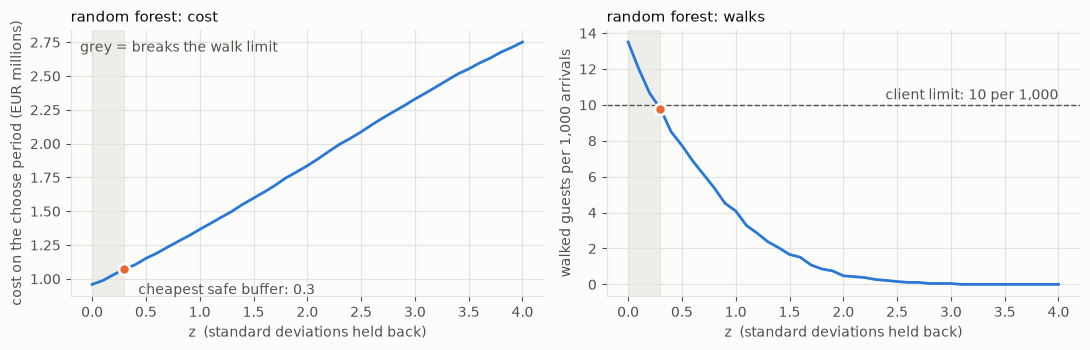

In [13]:
def nightly_error(nights):
    """Average gap, in rooms, between expected and real cancellations per night."""
    return (nights["expected"] - nights["cancelled"]).abs().mean()


nights_choose = contract.nightly_table(choose, chances_choose)      # one row per hotel and night
best_z, best = find_best_buffer(nights_choose)                       # the cheapest z inside the walk limit
rooms_held_back = avg_rooms_held_back(nights_choose, best_z)

print(f"Best buffer on the choose period: z = {best_z} std devs "
      f"= {rooms_held_back:.1f} rooms held back per night on average")
display(pd.Series({
    "cost (EUR)": best["cost_eur"],
    "empty rooms": best["empty_rooms"],
    "walked guests": best["walked_guests"],
    "walks per 1,000 arrivals": best["walks_per_1000"],
    "walk limit met (<= 10)": best["ceiling_met"],
    "nights scored": best["nights"],
    "nightly error (rooms)": round(nightly_error(nights_choose), 2),
}, name="random forest on the choose period").to_frame())

sweep = sweep_buffers(nights_choose)
plot_buffer_sweep(sweep, best_z, "z  (standard deviations held back)", "random forest")

**Reading the chart.** Cost rises with `z` (more empty rooms) while walks fall. The grey zone is every `z` that walks too many guests, so it is not allowed even though it is cheaper. The orange dot is the cheapest `z` just outside it.

### The client's flat rule (the yardstick)

The contract says every saving is a saving **against the client's flat rule**, never against selling nothing extra. The flat rule gives each booking its hotel's average cancellation rate from train, then holds back a fixed number of rooms (its margin, chosen on the choose period under the same walk limit).

In [14]:
# The client's flat rule is only a yardstick (it is not one of our models):
#   chance of cancelling = that hotel's cancellation rate in TRAIN, k = floor(rate x bookings) - margin.
# Every saving is measured against it, never against "sell nothing extra".
hotel_rate = train.groupby("hotel")["is_canceled"].mean()


def flat_rule_nights(df):
    chances = df["hotel"].map(hotel_rate).to_numpy()       # every booking gets its hotel's average rate
    return contract.nightly_table(df, chances)


flat_choose = flat_rule_nights(choose)
flat_margin, flat_best = find_best_buffer(flat_choose, kind="margin")
print(f"Client's flat rule: hotel rates from train {hotel_rate.round(3).to_dict()}")
print(f"Best safety margin on the choose period: {flat_margin} rooms  "
      f"(cost EUR {flat_best['cost_eur']:,.0f}, walks per 1,000 {flat_best['walks_per_1000']})")


comparison = pd.DataFrame([
    {"rule": "client's flat rule", "buffer": f"{flat_margin} rooms",
     "cost EUR": flat_best["cost_eur"], "empty rooms": flat_best["empty_rooms"],
     "walked guests": flat_best["walked_guests"], "walks per 1,000": flat_best["walks_per_1000"],
     "limit met": flat_best["ceiling_met"], "saving vs flat rule EUR": 0.0},
    {"rule": "random forest + z-buffer", "buffer": f"z = {best_z} (~{rooms_held_back:.1f} rooms)",
     "cost EUR": best["cost_eur"], "empty rooms": best["empty_rooms"],
     "walked guests": best["walked_guests"], "walks per 1,000": best["walks_per_1000"],
     "limit met": best["ceiling_met"], "saving vs flat rule EUR": flat_best["cost_eur"] - best["cost_eur"]},
]).set_index("rule")
display(comparison)

Client's flat rule: hotel rates from train {'City Hotel': 0.417, 'Resort Hotel': 0.252}
Best safety margin on the choose period: 16 rooms  (cost EUR 2,416,541, walks per 1,000 9.25)


,buffer,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,
client's flat rule,16 rooms,2416540.66,5529,172,9.25,True,0.00
random forest + z-buffer,z = 0.3 (~1.0 rooms),1071986.12,2443,182,9.79,True,1344554.54


### Do bookings on the same night cancel independently?

Every one of these models (and the contract's `spread`) assumes **independent bookings**. That cannot be tested before the model exists, so we test it now. If bookings are independent, the real night-to-night gap `cancelled − expected` should have the same variance as the contract's `spread²`, a ratio of about 1.

In [15]:
gap = nights_choose["cancelled"] - nights_choose["expected"]
variance_ratio = gap.var() / (nights_choose["spread"] ** 2).mean()
print(f"real variance of (cancelled - expected) / variance the contract assumes = {variance_ratio:.1f}")
if variance_ratio <= 1.5:
    print("About 1: bookings behave as if independent, so the spread is a fair measure of the risk.")
else:
    print(f"Well above 1: bookings on the same night cancel more together than independence allows, so the "
          f"real swings are about {variance_ratio ** 0.5:.1f}x bigger than `spread` says.\n"
          "The independence assumption is only roughly true. This is not a reason to stop, but it is why "
          "the buffer z is FOUND by search on the choose period instead of being taken from a textbook "
          "value like 1.64.")

real variance of (cancelled - expected) / variance the contract assumes = 6.1
Well above 1: bookings on the same night cancel more together than independence allows, so the real swings are about 2.5x bigger than `spread` says.
The independence assumption is only roughly true. This is not a reason to stop, but it is why the buffer z is FOUND by search on the choose period instead of being taken from a textbook value like 1.64.


## 7. Proof: the final exam (run once, at the very end)

The contract allows **one** look at the proof period (1 January to 31 August 2017). We use the model exactly as trained above and the `z` and margin chosen on the choose period. **Nothing is changed after seeing the result.** If you do change something afterwards, the contract says to report both runs.

Set `RUN_PROOF = True` in the switches cell only when everything else is final.

In [16]:
if not RUN_PROOF:
    print("RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.")
    proof_row = None
else:
    chances_proof = predict_chances(model, proof)
    proof_scores = get_scores(proof, chances_proof)
    nights_proof = contract.nightly_table(proof, chances_proof)
    model_proof = contract.night_cost(nights_proof, calculate_k(nights_proof, best_z))          # the z chosen earlier

    flat_nights_proof = flat_rule_nights(proof)
    flat_proof = contract.night_cost(flat_nights_proof, calculate_k(flat_nights_proof, flat_margin, "margin"))

    proof_row = pd.DataFrame([
        {"rule": "client's flat rule", "accuracy": None, "AUC": None, "cost EUR": flat_proof["cost_eur"],
         "empty rooms": flat_proof["empty_rooms"], "walked guests": flat_proof["walked_guests"],
         "walks per 1,000": flat_proof["walks_per_1000"], "limit met": flat_proof["ceiling_met"],
         "saving vs flat rule EUR": 0.0},
        {"rule": "random forest + z-buffer", "accuracy": proof_scores["accuracy"], "AUC": proof_scores["auc"],
         "cost EUR": model_proof["cost_eur"], "empty rooms": model_proof["empty_rooms"],
         "walked guests": model_proof["walked_guests"], "walks per 1,000": model_proof["walks_per_1000"],
         "limit met": model_proof["ceiling_met"],
         "saving vs flat rule EUR": flat_proof["cost_eur"] - model_proof["cost_eur"]},
    ]).set_index("rule")
    display(proof_row.round(3))

RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.


## 8. One-line summary

In [17]:
summary = pd.Series({
    "model": "random forest",
    "assumptions": verdict,
    "accuracy (choose)": round(scores["accuracy"], 3),
    "always-'stays' accuracy": round(scores["always_stays"], 3),
    "AUC (choose)": round(scores["auc"], 3),
    "z chosen (std devs)": best_z,
    "cost EUR (choose)": best["cost_eur"],
    "walks per 1,000 (choose)": best["walks_per_1000"],
    "walk limit met": best["ceiling_met"],
    "saving vs flat rule EUR (choose)": round(flat_best["cost_eur"] - best["cost_eur"], 2),
    "proof run": "done" if RUN_PROOF else "not run",
}, name="result")
display(summary.to_frame())

,result
model,random forest
assumptions,PASS
accuracy (choose),0.732
always-'stays' accuracy,0.631
AUC (choose),0.84
z chosen (std devs),0.3
cost EUR (choose),1071986.12
"walks per 1,000 (choose)",9.79
walk limit met,True
saving vs flat rule EUR (choose),1344554.54
